# Lab Program 1 — Gradient Descent Variants, Optimizers, Regularization and Residual MLPs

**Course:** Deep Learning Lab — Self Learning / Continuous Evaluation

**Aim**
1. Demonstrate **batch**, **stochastic** and **mini-batch** gradient descent on a small dataset.
2. Using an **MLP** on a subset of **Fashion-MNIST**, compare **momentum-based** (SGD + Momentum, Nesterov) and
   **adaptive** (RMSprop, Adam) optimizers with **constant** and **scheduled** learning rates.
3. **Investigate overfitting** and evaluate **dropout**, **L2 regularization** and **data augmentation**; apply **early stopping**.
4. Compare **plain** and **residual** MLPs under controlled training conditions.

| Part | Topic |
|---|---|
| A | Batch vs. stochastic vs. mini-batch gradient descent (NumPy, from scratch) |
| B | Optimizers × learning-rate schedules on an MLP |
| C | Overfitting, dropout, L2, data augmentation, early stopping |
| D | Plain vs. residual MLPs at increasing depth |

In [1]:
import time, math, copy, random, warnings
from collections import defaultdict
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import datasets
datasets.disable_progress_bars()

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()

# Small MLPs train faster on CPU than on a GPU (kernel-launch overhead dominates), and CPU runs are reproducible.
device = "cpu"
print("PyTorch:", torch.__version__, "| NumPy:", np.__version__, "| device:", device)

PyTorch: 2.15.0 | NumPy: 2.5.4 | device: cpu


---
## Part A — Batch, Stochastic and Mini-batch Gradient Descent

**Small dataset:** 200 points from a noisy line $y = 3x + 2 + \varepsilon,\; \varepsilon\sim\mathcal N(0,1)$.
**Model:** $\hat y = w x + b$ with loss $L(w,b) = \frac{1}{2m}\sum_{i\in B}(w x_i + b - y_i)^2$ over a batch $B$ of size $m$.

$$
\frac{\partial L}{\partial w} = \frac1m\sum_{i\in B}(\hat y_i - y_i)\,x_i,\qquad
\frac{\partial L}{\partial b} = \frac1m\sum_{i\in B}(\hat y_i - y_i),\qquad
\theta \leftarrow \theta - \eta\,\nabla_\theta L
$$

| Variant | Batch size $m$ | Updates per epoch | Character |
|---|---|---|---|
| **Batch GD** | $N$ (all data) | 1 | exact gradient, smooth but slow per epoch, expensive per step |
| **Stochastic GD** | 1 | $N$ | very noisy, cheap steps, many updates per epoch |
| **Mini-batch GD** | e.g. 16 | $N/m$ | compromise: low-ish noise, vectorised, the standard in deep learning |

All variants below are implemented from scratch in NumPy and start from the same point $(w,b)=(-2,-3)$.

In [2]:
rng = np.random.default_rng(0)
N = 200
x_small = rng.uniform(-2, 2, N)
y_small = 3 * x_small + 2 + rng.normal(0, 1, N)

def full_loss(w, b):
    return 0.5 * np.mean((w * x_small + b - y_small) ** 2)

w_opt, b_opt = np.polyfit(x_small, y_small, 1)          # closed-form least squares
print(f"Closed-form optimum: w = {w_opt:.4f}, b = {b_opt:.4f}, loss = {full_loss(w_opt, b_opt):.4f}")


def gradient_descent(batch_size, lr, epochs, w0=-2.0, b0=-3.0, seed=0):
    # Generic mini-batch GD; batch_size=N gives batch GD, batch_size=1 gives SGD.
    r = np.random.default_rng(seed)
    w, b = w0, b0
    path, epoch_loss, update_loss = [(w, b)], [full_loss(w, b)], [full_loss(w, b)]
    t0 = time.perf_counter()
    for _ in range(epochs):
        idx = r.permutation(N)                          # reshuffle every epoch
        for s in range(0, N, batch_size):
            bi = idx[s:s + batch_size]
            err = w * x_small[bi] + b - y_small[bi]
            w -= lr * np.mean(err * x_small[bi])
            b -= lr * np.mean(err)
            path.append((w, b)); update_loss.append(full_loss(w, b))
        epoch_loss.append(full_loss(w, b))
    return dict(path=np.array(path), epoch_loss=np.array(epoch_loss),
                update_loss=np.array(update_loss), time=time.perf_counter() - t0, w=w, b=b)


EPOCHS_A = 30
variants = {
    "Batch GD (m=200, η=0.05)":     dict(batch_size=N,  lr=0.05),
    "Batch GD (m=200, η=0.5)":      dict(batch_size=N,  lr=0.5),
    "Mini-batch GD (m=16, η=0.05)": dict(batch_size=16, lr=0.05),
    "Stochastic GD (m=1, η=0.05)":  dict(batch_size=1,  lr=0.05),
}
res_A = {name: gradient_descent(epochs=EPOCHS_A, **cfg) for name, cfg in variants.items()}

print(f"\n{'variant':32s} {'updates':>8s} {'final loss':>11s} {'w':>7s} {'b':>7s} {'time (ms)':>10s}")
for name, r in res_A.items():
    print(f"{name:32s} {len(r['path'])-1:8d} {r['epoch_loss'][-1]:11.4f} {r['w']:7.3f} {r['b']:7.3f} {r['time']*1e3:10.1f}")

Closed-form optimum: w = 2.9367, b = 1.9206, loss = 0.5211

variant                           updates  final loss       w       b  time (ms)
Batch GD (m=200, η=0.05)               30      1.0430   2.612   1.028        0.4
Batch GD (m=200, η=0.5)                30      0.5211   2.937   1.921        0.3
Mini-batch GD (m=16, η=0.05)          390      0.5211   2.942   1.924        2.3
Stochastic GD (m=1, η=0.05)          6000      0.5421   2.767   1.928       35.2


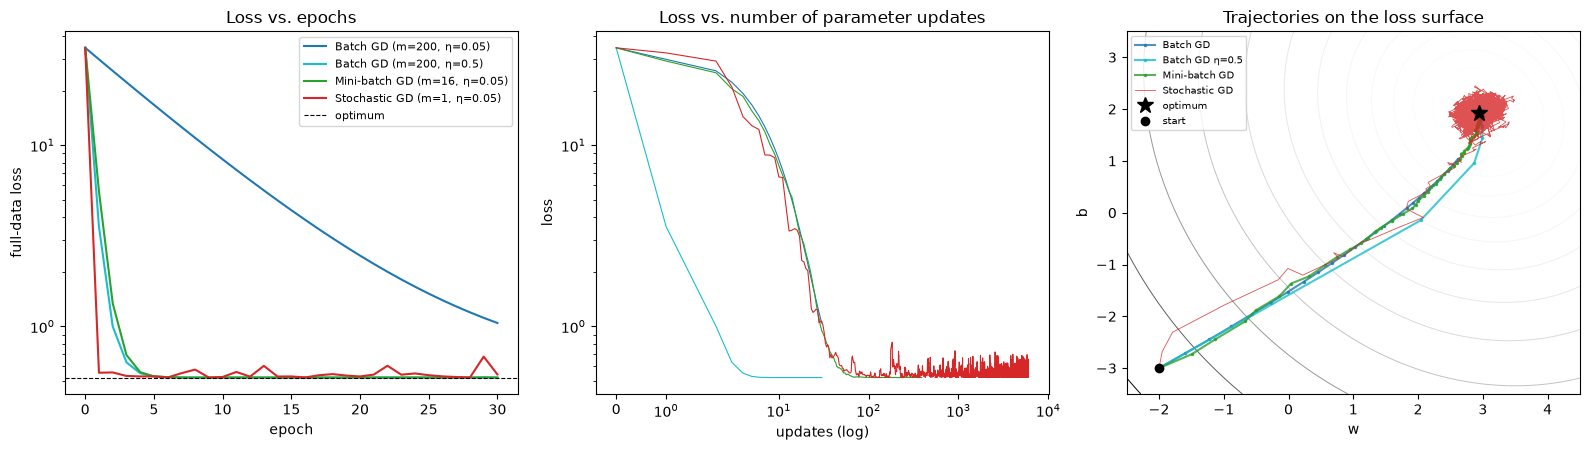

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
colors = ["tab:blue", "tab:cyan", "tab:green", "tab:red"]
for (name, r), c in zip(res_A.items(), colors):
    axes[0].plot(r["epoch_loss"], label=name, color=c)
    axes[1].plot(np.arange(len(r["update_loss"])), r["update_loss"], color=c, lw=0.8)
axes[0].axhline(full_loss(w_opt, b_opt), ls="--", c="k", lw=0.8, label="optimum")
axes[0].set(title="Loss vs. epochs", xlabel="epoch", ylabel="full-data loss", yscale="log"); axes[0].legend(fontsize=8)
axes[1].set(title="Loss vs. number of parameter updates", xlabel="updates (log)", ylabel="loss",
            xscale="symlog", yscale="log")

W, B = np.meshgrid(np.linspace(-2.5, 4.5, 200), np.linspace(-3.5, 3.5, 200))
Z = 0.5 * np.mean((W[..., None] * x_small + B[..., None] - y_small) ** 2, axis=-1)
axes[2].contour(W, B, Z, levels=np.logspace(-0.5, 1.6, 15), cmap="Greys", linewidths=0.7)
for (name, r), c in zip(res_A.items(), colors):
    p = r["path"]
    axes[2].plot(p[:, 0], p[:, 1], color=c, lw=0.6 if "Stochastic" in name else 1.5, marker="." if len(p) < 400 else None,
                 ms=3, alpha=0.8, label=name.split(" (")[0] + (" η=0.5" if "0.5" in name else ""))
axes[2].plot(w_opt, b_opt, "k*", ms=12, label="optimum"); axes[2].plot(-2, -3, "ko", label="start")
axes[2].set(title="Trajectories on the loss surface", xlabel="w", ylabel="b"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Gradient noise vs. batch size.** A mini-batch gradient is an unbiased estimate of the full gradient whose standard
deviation falls roughly as $1/\sqrt m$ (with a finite-population correction as $m\to N$). This noise is why SGD zig-zags,
and it is also the reason a smaller learning rate (or a decaying schedule) is needed for SGD to settle at the minimum.

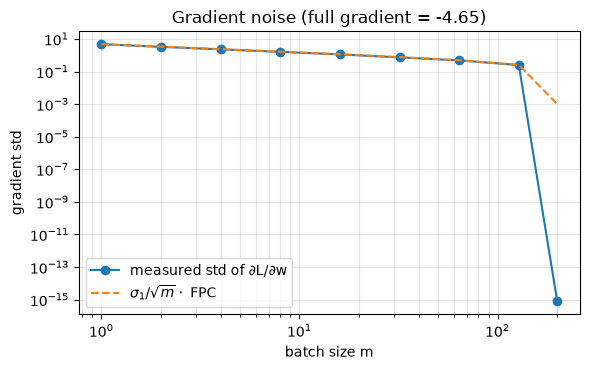

In [4]:
w0, b0 = 0.0, 0.0
full_g = np.mean((w0 * x_small + b0 - y_small) * x_small)
sizes = [1, 2, 4, 8, 16, 32, 64, 128, 200]
stds = []
r = np.random.default_rng(1)
for m in sizes:
    g = []
    for _ in range(2000):
        bi = r.choice(N, m, replace=False)
        g.append(np.mean((w0 * x_small[bi] + b0 - y_small[bi]) * x_small[bi]))
    stds.append(np.std(g))
theory = stds[0] / np.sqrt(sizes) * np.sqrt((N - np.array(sizes)) / (N - 1))
plt.figure(figsize=(6, 3.8))
plt.loglog(sizes, stds, "o-", label="measured std of ∂L/∂w")
plt.loglog(sizes, np.maximum(theory, 1e-3), "--", label=r"$\sigma_1/\sqrt{m}\cdot$ FPC")
plt.xlabel("batch size m"); plt.ylabel("gradient std"); plt.title(f"Gradient noise (full gradient = {full_g:.2f})")
plt.legend(); plt.grid(alpha=.3, which="both"); plt.tight_layout(); plt.show()

**Observations (Part A)**
* With the same learning rate, **batch GD** makes only one step per epoch, so after 30 epochs it is still far from the optimum;
  a 10× larger step (η=0.5) is needed to converge, and that is only possible because its gradient is exact.
* **SGD** makes 200 updates per epoch and gets close to the optimum within the first epoch, but then **jitters** around it
  because each step uses one noisy example — the final loss is slightly above the optimum.
* **Mini-batch GD** converges almost as fast per epoch as SGD with a much smoother path and vectorised computation;
  this is why it is the default for training neural networks.

---
## Fashion-MNIST subset

Fashion-MNIST (Zalando) has 70 000 grayscale 28×28 images of 10 clothing classes. It is loaded from the Hugging Face Hub
(`zalando-datasets/fashion_mnist`). To keep every experiment fast and to make overfitting visible, a **class-balanced
subset** is used:

* **train:** 6 000 images (600 per class) · **validation:** 2 000 images (200 per class), both drawn from the original training split
* **test:** the full official 10 000-image test split (used only for final reporting)

Pixels are scaled to [0, 1] and standardised with the training-subset mean and standard deviation; images are flattened to 784-D vectors for the MLPs.

train (6000, 784)  val (2000, 784)  test (10000, 784)   (mean 0.2874, std 0.3536)
train class counts: [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]


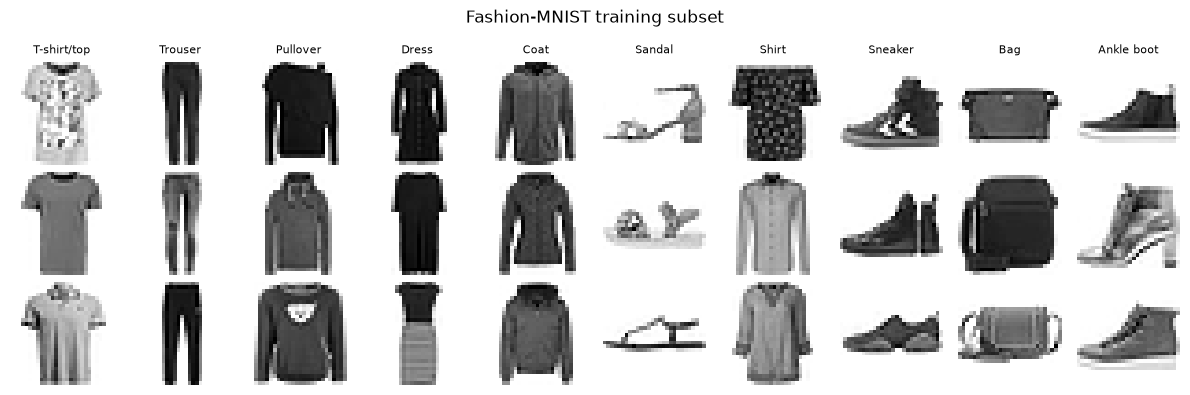

In [5]:
from datasets import load_dataset

fm = load_dataset("zalando-datasets/fashion_mnist")
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def to_numpy(split):
    d = fm[split].with_format("numpy")
    return np.stack(d["image"]).astype(np.float32) / 255.0, np.asarray(d["label"]).astype(np.int64)

X_all, y_all = to_numpy("train")
X_test_np, y_test_np = to_numpy("test")

r = np.random.default_rng(SEED)
tr_idx, va_idx = [], []
for c in range(10):
    idx = r.permutation(np.where(y_all == c)[0])
    tr_idx += list(idx[:600]); va_idx += list(idx[600:800])
tr_idx, va_idx = r.permutation(tr_idx), r.permutation(va_idx)

mu, sigma = X_all[tr_idx].mean(), X_all[tr_idx].std()
def prep(X):
    return torch.tensor(((X - mu) / sigma).reshape(len(X), -1), device=device)

Xtr, ytr = prep(X_all[tr_idx]), torch.tensor(y_all[tr_idx], device=device)
Xva, yva = prep(X_all[va_idx]), torch.tensor(y_all[va_idx], device=device)
Xte, yte = prep(X_test_np), torch.tensor(y_test_np, device=device)
print(f"train {tuple(Xtr.shape)}  val {tuple(Xva.shape)}  test {tuple(Xte.shape)}   (mean {mu:.4f}, std {sigma:.4f})")
print("train class counts:", np.bincount(ytr.numpy()).tolist())

fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for c in range(10):
    ids = np.where(y_all[tr_idx] == c)[0][:3]
    for k, i in enumerate(ids):
        axes[k, c].imshow(X_all[tr_idx][i], cmap="gray_r"); axes[k, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.suptitle("Fashion-MNIST training subset"); plt.tight_layout(); plt.show()

### Shared training utilities

One `train()` function is used for every experiment in Parts B–D so that **only the factor being studied changes**.
It supports a learning-rate scheduler, explicit L2 penalty, data augmentation and early stopping, and records the
**clean** (non-augmented, eval-mode) train / validation loss and accuracy after every epoch.

In [6]:
def make_mlp(hidden=(256, 128), p_drop=0.0, in_dim=784, n_out=10):
    layers, d = [], in_dim
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        d = h
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers).to(device)


@torch.no_grad()
def evaluate(model, X, y, bs=2000):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)


def augment_batch(xb, max_shift=2, max_rot=10):
    # Per-sample random rotation (±max_rot°), translation (±max_shift px) and horizontal flip, via an affine grid.
    B = xb.size(0)
    img = xb.view(B, 1, 28, 28)
    ang = (torch.rand(B, device=xb.device) * 2 - 1) * math.radians(max_rot)
    t = (torch.rand(B, 2, device=xb.device) * 2 - 1) * (2 * max_shift / 28)   # pixels -> normalised coords
    flip = torch.where(torch.rand(B, device=xb.device) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([torch.stack([cos * flip, -sin, t[:, 0]], 1),
                         torch.stack([sin * flip,  cos, t[:, 1]], 1)], 1)
    grid = F.affine_grid(theta, img.shape, align_corners=False)
    return F.grid_sample(img, grid, padding_mode="border", align_corners=False).view(B, -1)


def l2_penalty(model):
    # Sum of squared weights (biases excluded).
    return sum((p ** 2).sum() for name, p in model.named_parameters() if p.ndim > 1)


def train(model, optimizer, epochs, scheduler=None, batch_size=64, l2=0.0, augment=False,
          patience=None, X=None, y=None, seed=SEED, verbose=False):
    X = Xtr if X is None else X
    y = ytr if y is None else y
    g = torch.Generator(device="cpu").manual_seed(seed)
    hist = defaultdict(list)
    best_loss, best_state, wait = float("inf"), None, 0
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X[idx], y[idx]
            if augment:
                xb = augment_batch(xb)
            loss = F.cross_entropy(model(xb), yb)
            if l2 > 0:
                loss = loss + l2 * l2_penalty(model)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        if scheduler is not None:
            scheduler.step()
        for split, (Xs, ys) in {"train": (X, y), "val": (Xva, yva)}.items():
            l, a = evaluate(model, Xs, ys)
            hist[f"{split}_loss"].append(l); hist[f"{split}_acc"].append(a)
        if verbose and (ep % 10 == 0 or ep == 1):
            print(f"  ep {ep:3d} train {hist['train_acc'][-1]*100:5.1f}%  val {hist['val_acc'][-1]*100:5.1f}%")
        if patience is not None:
            if hist["val_loss"][-1] < best_loss - 1e-4:
                best_loss, best_state, wait = hist["val_loss"][-1], copy.deepcopy(model.state_dict()), 0
                hist["best_epoch"] = ep
            else:
                wait += 1
                if wait >= patience:
                    hist["stopped_epoch"] = ep
                    break
    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)           # restore the best weights
    hist["time"] = time.perf_counter() - t0
    return hist

---
## Part B — Momentum-based and adaptive optimizers × learning-rate schedules

Update rules (gradient $g_t$, learning rate $\eta_t$):

| Optimizer | Update |
|---|---|
| **SGD** (baseline) | $\theta_{t+1} = \theta_t - \eta_t g_t$ |
| **SGD + Momentum** | $v_{t+1} = \mu v_t + g_t,\quad \theta_{t+1} = \theta_t - \eta_t v_{t+1}$ |
| **Nesterov (NAG)** | gradient evaluated at the look-ahead point: $\theta_{t+1} = \theta_t - \eta_t\,(g_t + \mu v_{t+1})$ |
| **RMSprop** (adaptive) | $s_{t+1} = \rho s_t + (1-\rho) g_t^2,\quad \theta_{t+1} = \theta_t - \eta_t\, g_t / (\sqrt{s_{t+1}}+\epsilon)$ |
| **Adam** (momentum + adaptive) | $m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\; v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2,\; \theta_{t+1}=\theta_t-\eta_t\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$ |

**Learning-rate schedules** (stepped once per epoch):
* **Constant** — $\eta_t = \eta_0$
* **Step decay** — $\eta$ multiplied by 0.3 every 8 epochs
* **Cosine annealing** — $\eta_t = \tfrac{\eta_0}{2}\left(1 + \cos\frac{\pi t}{T}\right)$

**Controlled setup:** MLP 784-256-128-10 (ReLU), batch size 64, 25 epochs, identical initial weights and data order for every run.
Base learning rates are the usual defaults for each family (0.05 for SGD-type, 0.001 for adaptive).

In [7]:
EPOCHS_B = 25
OPTIMIZERS = {
    "SGD":            lambda p: torch.optim.SGD(p, lr=0.05),
    "SGD+Momentum":   lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "Nesterov":       lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, nesterov=True),
    "RMSprop":        lambda p: torch.optim.RMSprop(p, lr=1e-3),
    "Adam":           lambda p: torch.optim.Adam(p, lr=1e-3),
}
SCHEDULES = {
    "constant": lambda o: None,
    "step":     lambda o: torch.optim.lr_scheduler.StepLR(o, step_size=8, gamma=0.3),
    "cosine":   lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=EPOCHS_B),
}

set_seed(); init_state = make_mlp().state_dict()       # same initial weights for every run
res_B = {}
for o_name, make_opt in OPTIMIZERS.items():
    for s_name, make_sched in SCHEDULES.items():
        model = make_mlp(); model.load_state_dict(init_state)
        opt = make_opt(model.parameters())
        h = train(model, opt, EPOCHS_B, scheduler=make_sched(opt))
        h["test_loss"], h["test_acc"] = evaluate(model, Xte, yte)
        res_B[(o_name, s_name)] = h
        print(f"{o_name:13s} {s_name:8s} | best val {max(h['val_acc'])*100:5.2f}%  final val {h['val_acc'][-1]*100:5.2f}%  "
              f"test {h['test_acc']*100:5.2f}%  ({h['time']:.1f}s)")

SGD           constant | best val 85.35%  final val 81.90%  test 80.83%  (0.7s)


SGD           step     | best val 85.45%  final val 85.40%  test 84.72%  (0.6s)


SGD           cosine   | best val 85.75%  final val 85.75%  test 84.86%  (0.6s)


SGD+Momentum  constant | best val 85.40%  final val 83.70%  test 83.05%  (0.7s)


SGD+Momentum  step     | best val 86.20%  final val 85.55%  test 85.40%  (0.7s)


SGD+Momentum  cosine   | best val 86.40%  final val 85.80%  test 85.32%  (0.7s)


... (5 outputs left out)

RMSprop       cosine   | best val 86.20%  final val 85.65%  test 85.63%  (0.9s)


Adam          constant | best val 85.75%  final val 84.45%  test 84.03%  (1.1s)


Adam          step     | best val 86.30%  final val 85.75%  test 85.25%  (1.1s)


Adam          cosine   | best val 86.10%  final val 85.70%  test 85.30%  (1.1s)


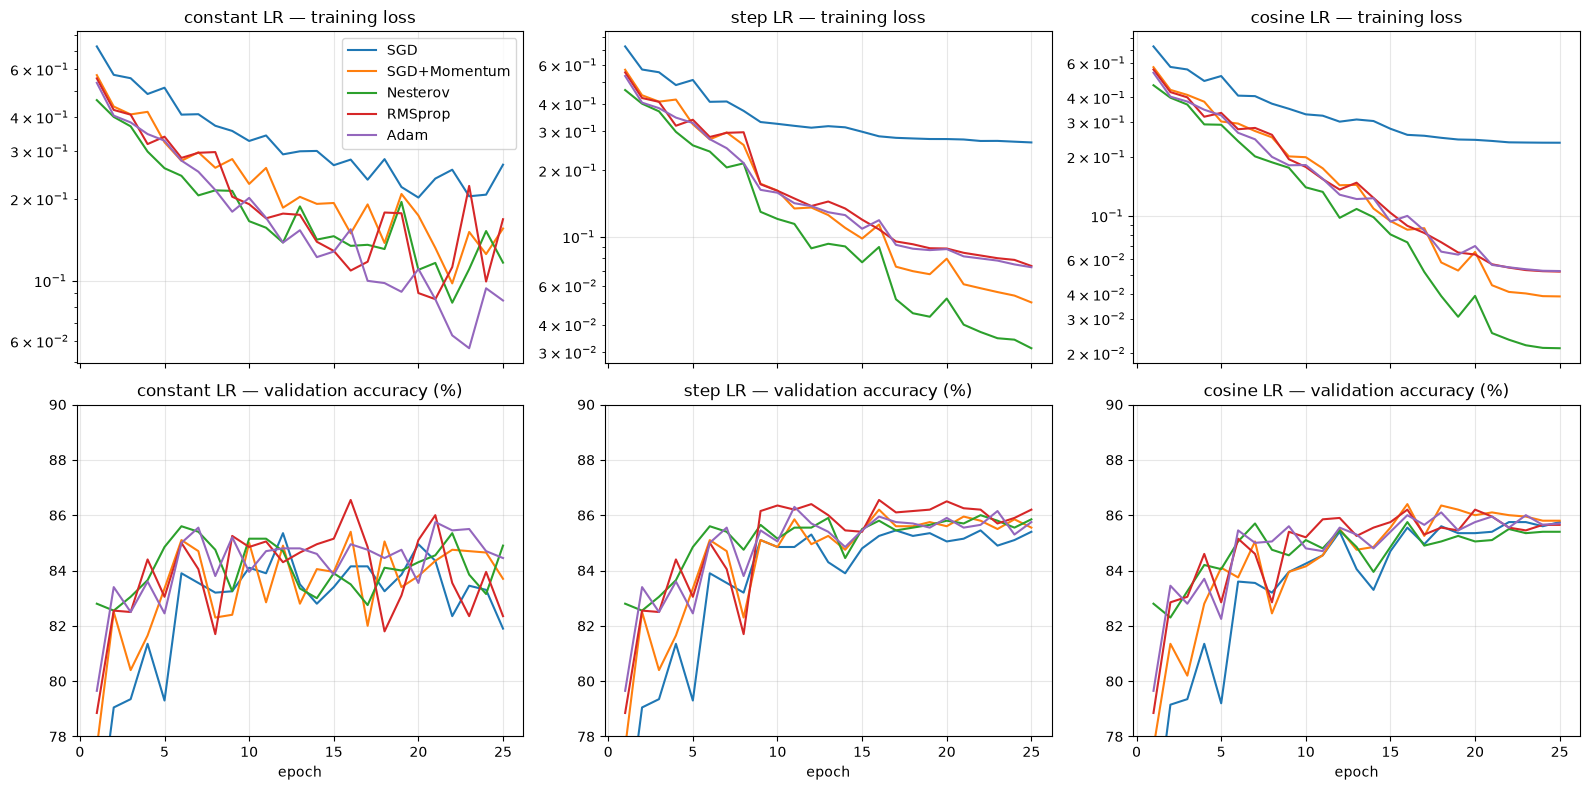

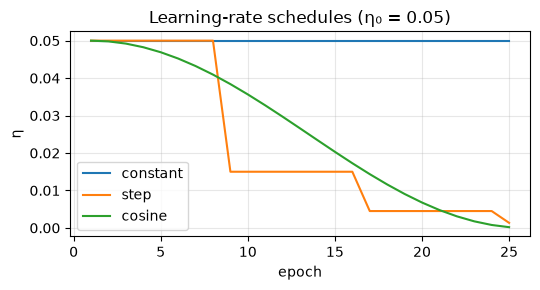

In [8]:
ep = np.arange(1, EPOCHS_B + 1)
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for j, s_name in enumerate(SCHEDULES):
    for o_name in OPTIMIZERS:
        h = res_B[(o_name, s_name)]
        axes[0, j].plot(ep, h["train_loss"], label=o_name)
        axes[1, j].plot(ep, np.array(h["val_acc"]) * 100, label=o_name)
    axes[0, j].set(title=f"{s_name} LR — training loss", yscale="log")
    axes[1, j].set(title=f"{s_name} LR — validation accuracy (%)", xlabel="epoch", ylim=(78, 90))
    for a in axes[:, j]: a.grid(alpha=.3)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(5.5, 3))
for s_name in SCHEDULES:
    plt.plot(ep, res_B[("SGD+Momentum", s_name)]["lr"], label=s_name)
plt.title("Learning-rate schedules (η₀ = 0.05)"); plt.xlabel("epoch"); plt.ylabel("η"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

optimizer     schedule  final train loss  best val  final val    test  ep→85% val
SGD           constant            0.2670    85.35%     81.90%  80.83%          12
SGD           step                0.2672    85.45%     85.40%  84.72%           9
SGD           cosine              0.2354    85.75%     85.75%  84.86%          12
SGD+Momentum  constant            0.1555    85.40%     83.70%  83.05%           6
SGD+Momentum  step                0.0504    86.20%     85.55%  85.40%           6
SGD+Momentum  cosine              0.0389    86.40%     85.80%  85.32%           7
Nesterov      constant            0.1165    85.60%     84.90%  83.63%           6
Nesterov      step                0.0312    86.00%     85.85%  85.15%           6
Nesterov      cosine              0.0212    85.75%     85.40%  85.09%           6
RMSprop       constant            0.1683    86.55%     82.35%  81.24%           6
RMSprop       step                0.0737    86.55%     86.20%  85.71%           6
RMSprop       co

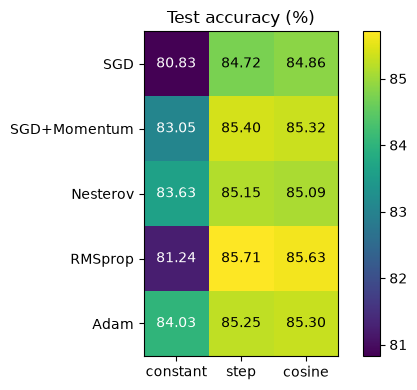

In [9]:
def epochs_to(h, thr=0.85):
    hit = np.where(np.array(h["val_acc"]) >= thr)[0]
    return str(hit[0] + 1) if len(hit) else "—"

print(f"{'optimizer':13s} {'schedule':9s} {'final train loss':>16s} {'best val':>9s} {'final val':>10s} {'test':>7s} {'ep→85% val':>11s}")
for (o, s), h in res_B.items():
    print(f"{o:13s} {s:9s} {h['train_loss'][-1]:16.4f} {max(h['val_acc'])*100:8.2f}% {h['val_acc'][-1]*100:9.2f}% "
          f"{h['test_acc']*100:6.2f}% {epochs_to(h):>11s}")

mat = np.array([[res_B[(o, s)]["test_acc"] * 100 for s in SCHEDULES] for o in OPTIMIZERS])
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(mat, cmap="viridis")
ax.set_xticks(range(len(SCHEDULES)), list(SCHEDULES)); ax.set_yticks(range(len(OPTIMIZERS)), list(OPTIMIZERS))
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="w" if mat[i, j] < mat.mean() else "k")
ax.set_title("Test accuracy (%)"); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

**Observations (Part B)**
* **Plain SGD** is the slowest optimizer: it has the highest final training loss (0.24–0.27) and needs 9–12 epochs to reach 85 % validation accuracy.
  **Momentum** and **Nesterov** accumulate velocity along consistent gradient directions, cutting the training loss by 2–10× and reaching 85 % in about 6 epochs.
* The **adaptive** optimizers (**RMSprop**, **Adam**) also reach 85 % in 6 epochs. RMSprop has the highest peak validation accuracy (86.55 %),
  but with a constant learning rate it is the least stable: it ends at 82.35 % validation / 81.24 % test.
* With a **constant learning rate**, every optimizer finishes 0.7–4.2 pp below its own best validation accuracy, because the step stays too large to settle.
  **Step decay** and **cosine annealing** fix this: final validation accuracy is within ~0.7 pp of the best, and test accuracy improves by 1.3–4.5 pp
  (e.g. SGD 80.83 → 84.86 %, RMSprop 81.24 → 85.71 %).
* Best result: **RMSprop + step decay (85.71 % test)**, with Momentum, Nesterov and Adam plus a schedule all within ~0.6 pp.
  On this problem the learning-rate **schedule matters more than the choice of optimizer**.

---
## Part C — Overfitting and regularization

### C.1 Demonstrating overfitting
A large MLP (784-512-512-10, ≈ 670 k parameters) has far more capacity than 6 000 training images need.
Trained for 60 epochs with Adam (η = 1e-3) and **no regularization**, it memorises the training set: training loss → 0
while validation loss reaches a minimum and then **rises** — the classic signature of overfitting.

parameters: 669706


final train acc 99.25%  |  final val acc 84.90%
min val loss 0.4249 at epoch 6; final val loss 1.0746


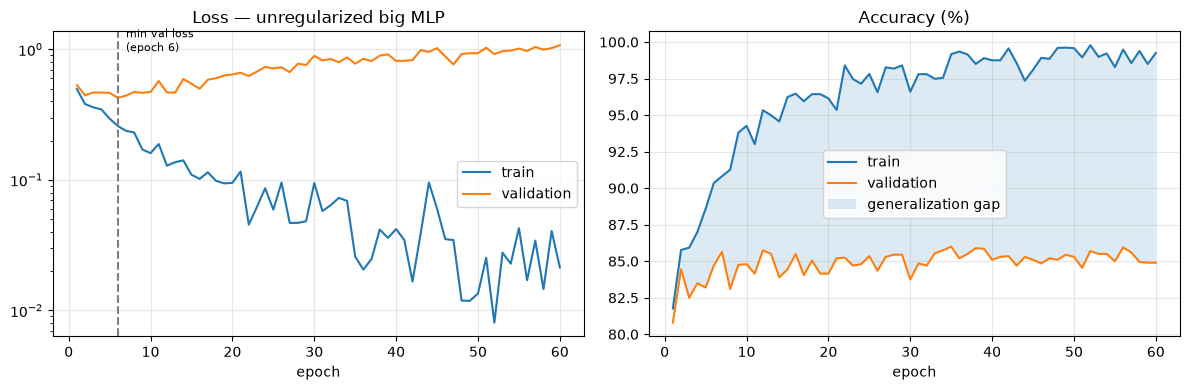

In [10]:
EPOCHS_C = 60
BIG = (512, 512)

def big_model(p_drop=0.0):
    set_seed()
    return make_mlp(BIG, p_drop=p_drop)

print("parameters:", sum(p.numel() for p in big_model().parameters()))

def run_C(p_drop=0.0, l2=0.0, augment=False, patience=None):
    model = big_model(p_drop)
    h = train(model, torch.optim.Adam(model.parameters(), lr=1e-3), EPOCHS_C, l2=l2, augment=augment, patience=patience)
    h["test_loss"], h["test_acc"] = evaluate(model, Xte, yte)
    return model, h

base_model, base = run_C()
best_ep = int(np.argmin(base["val_loss"])) + 1
print(f"final train acc {base['train_acc'][-1]*100:.2f}%  |  final val acc {base['val_acc'][-1]*100:.2f}%")
print(f"min val loss {min(base['val_loss']):.4f} at epoch {best_ep}; final val loss {base['val_loss'][-1]:.4f}")

e = np.arange(1, EPOCHS_C + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(e, base["train_loss"], label="train"); a1.plot(e, base["val_loss"], label="validation")
a1.axvline(best_ep, ls="--", c="gray"); a1.text(best_ep + 1, max(base["val_loss"]) * 0.9, f"min val loss\n(epoch {best_ep})", fontsize=8)
a1.set(title="Loss — unregularized big MLP", xlabel="epoch", yscale="log"); a1.legend(); a1.grid(alpha=.3)
a2.plot(e, np.array(base["train_acc"]) * 100, label="train"); a2.plot(e, np.array(base["val_acc"]) * 100, label="validation")
a2.fill_between(e, np.array(base["val_acc"]) * 100, np.array(base["train_acc"]) * 100, alpha=.15, label="generalization gap")
a2.set(title="Accuracy (%)", xlabel="epoch"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()

### C.2 Regularization techniques

* **Dropout** (p) — during training each hidden unit is zeroed with probability p (and the rest scaled by 1/(1−p)), so the
  network cannot rely on co-adapted units; at test time all units are used. Equivalent to training an ensemble of thinned networks.
* **L2 regularization** (λ) — adds $\lambda\sum w^2$ to the loss, pulling weights towards zero and favouring smoother functions.
  (With plain SGD this equals weight decay; with Adam it is applied through the gradient, as written here.)
* **Data augmentation** — random rotations (±10°), shifts (±2 px) and horizontal flips create new plausible training images every
  epoch, effectively enlarging the dataset.
* **Combination** of all three.

Each run uses the same initial weights, optimizer, learning rate, data order and 60 epochs as the baseline.

In [11]:
configs_C = {
    "Baseline (none)":        dict(),
    "Dropout p=0.2":          dict(p_drop=0.2),
    "Dropout p=0.5":          dict(p_drop=0.5),
    "L2 λ=1e-4":              dict(l2=1e-4),
    "L2 λ=1e-3":              dict(l2=1e-3),
    "Data augmentation":      dict(augment=True),
    "Dropout0.3+L2 1e-4+Aug": dict(p_drop=0.3, l2=1e-4, augment=True),
}
res_C, models_C = {"Baseline (none)": base}, {"Baseline (none)": base_model}
for name, cfg in configs_C.items():
    if name in res_C:
        continue
    models_C[name], res_C[name] = run_C(**cfg)
    print(f"{name:24s} done ({res_C[name]['time']:.0f}s)")

Dropout p=0.2            done (6s)


Dropout p=0.5            done (6s)


L2 λ=1e-4                done (6s)


L2 λ=1e-3                done (7s)


Data augmentation        done (8s)


Dropout0.3+L2 1e-4+Aug   done (11s)


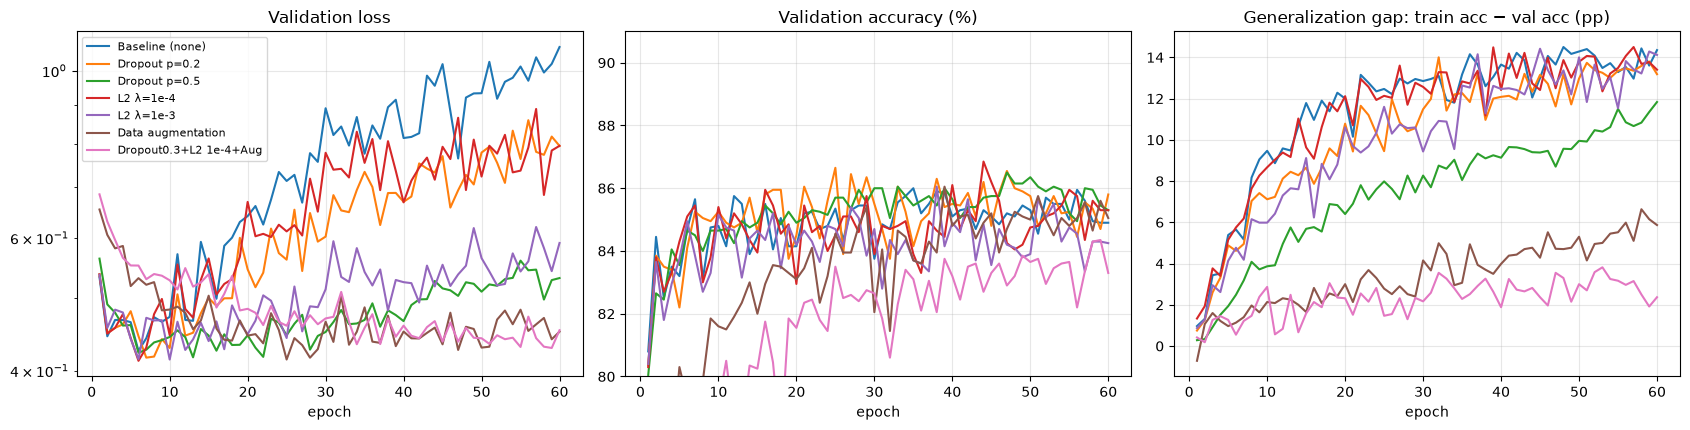

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for name, h in res_C.items():
    axes[0].plot(e, h["val_loss"], label=name)
    axes[1].plot(e, np.array(h["val_acc"]) * 100, label=name)
    axes[2].plot(e, (np.array(h["train_acc"]) - np.array(h["val_acc"])) * 100, label=name)
axes[0].set(title="Validation loss", xlabel="epoch", yscale="log")
axes[1].set(title="Validation accuracy (%)", xlabel="epoch", ylim=(80, 91))
axes[2].set(title="Generalization gap: train acc − val acc (pp)", xlabel="epoch")
for a in axes: a.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

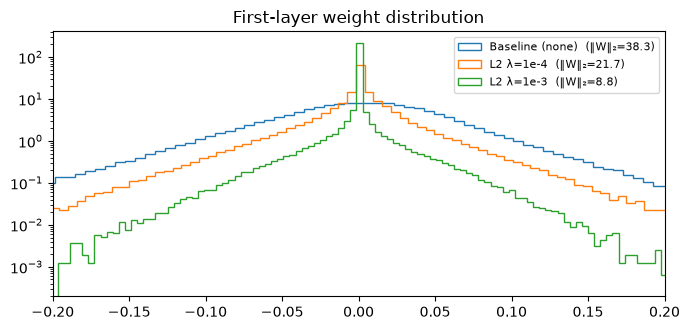

In [13]:
# Effect of L2 on the weight distribution of the first layer
plt.figure(figsize=(7, 3.4))
for name in ["Baseline (none)", "L2 λ=1e-4", "L2 λ=1e-3"]:
    w = models_C[name][0].weight.detach().flatten().numpy()
    plt.hist(w, bins=150, histtype="step", density=True, label=f"{name}  (‖W‖₂={np.linalg.norm(w):.1f})")
plt.xlim(-0.2, 0.2); plt.yscale("log"); plt.title("First-layer weight distribution"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### C.3 Early stopping

Early stopping monitors the validation loss, stops training when it has not improved for `patience` = 10 epochs, and
**restores the weights from the best epoch**. It is applied to the unregularized baseline and to the combined-regularization model.

Baseline + early stopping                  best epoch  6, stopped at epoch 16, test acc 83.80%


Dropout0.3+L2 1e-4+Aug + early stopping    best epoch 34, stopped at epoch 44, test acc 83.65%


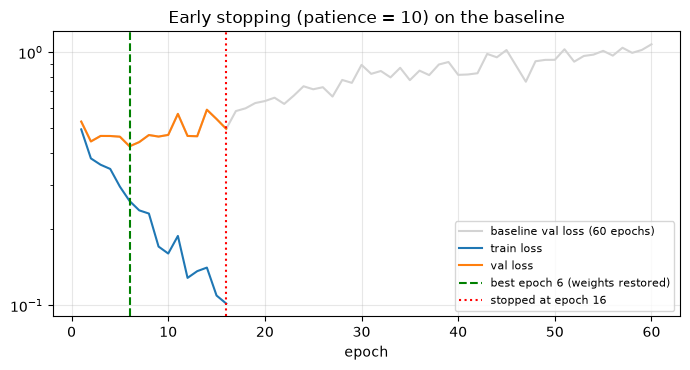

In [14]:
for name, cfg in {"Baseline + early stopping": dict(),
                  "Dropout0.3+L2 1e-4+Aug + early stopping": dict(p_drop=0.3, l2=1e-4, augment=True)}.items():
    models_C[name], res_C[name] = run_C(patience=10, **cfg)
    h = res_C[name]
    print(f"{name:42s} best epoch {h['best_epoch']:2d}, stopped at epoch {h.get('stopped_epoch', EPOCHS_C)}, "
          f"test acc {h['test_acc']*100:.2f}%")

h = res_C["Baseline + early stopping"]
ee = np.arange(1, len(h["val_loss"]) + 1)
plt.figure(figsize=(7, 3.8))
plt.plot(e, base["val_loss"], c="lightgray", label="baseline val loss (60 epochs)")
plt.plot(ee, h["train_loss"], label="train loss"); plt.plot(ee, h["val_loss"], label="val loss")
plt.axvline(h["best_epoch"], c="g", ls="--", label=f"best epoch {h['best_epoch']} (weights restored)")
plt.axvline(h["stopped_epoch"], c="r", ls=":", label=f"stopped at epoch {h['stopped_epoch']}")
plt.yscale("log"); plt.xlabel("epoch"); plt.title("Early stopping (patience = 10) on the baseline"); plt.legend(fontsize=8)
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

configuration                              epochs  train acc  val acc    gap  val loss  TEST acc
Baseline (none)                                60     99.25%   84.90%  14.4    1.0746    84.31%
Dropout p=0.2                                  60     98.98%   85.80%  13.2    0.7945    85.20%
Dropout p=0.5                                  60     97.13%   85.30%  11.8    0.5306    85.43%
L2 λ=1e-4                                      60     98.70%   85.30%  13.4    0.7947    84.25%
L2 λ=1e-3                                      60     98.37%   84.25%  14.1    0.5906    83.87%
Data augmentation                              60     90.92%   85.05%   5.9    0.4504    84.10%
Dropout0.3+L2 1e-4+Aug                         60     85.67%   83.30%   2.4    0.4525    83.24%
Baseline + early stopping                      16     90.35%   84.70%   5.6    0.4249    83.80%
Dropout0.3+L2 1e-4+Aug + early stopping        44     86.20%   83.40%   2.8    0.4335    83.65%


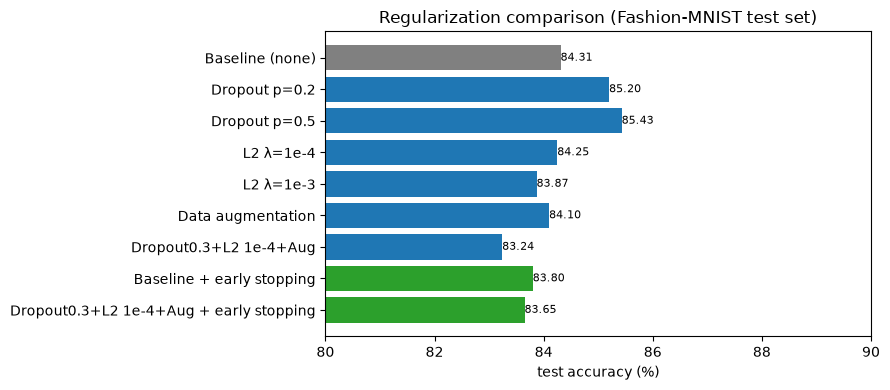

In [15]:
print(f"{'configuration':42s} {'epochs':>6s} {'train acc':>10s} {'val acc':>8s} {'gap':>6s} {'val loss':>9s} {'TEST acc':>9s}")
rows = []
for name, h in res_C.items():
    # final-epoch numbers; for early stopping, the restored best epoch
    k = h["best_epoch"] - 1 if "best_epoch" in h else -1
    tr, va, vl = h["train_acc"][k], h["val_acc"][k], h["val_loss"][k]
    rows.append((name, h["test_acc"]))
    print(f"{name:42s} {len(h['val_acc']):6d} {tr*100:9.2f}% {va*100:7.2f}% {(tr-va)*100:5.1f} {vl:9.4f} {h['test_acc']*100:8.2f}%")

names, accs = zip(*rows)
plt.figure(figsize=(9, 4))
bars = plt.barh(names, np.array(accs) * 100, color=["gray"] + ["tab:blue"] * 6 + ["tab:green"] * 2)
plt.bar_label(bars, fmt="%.2f", fontsize=8); plt.xlim(80, 90); plt.gca().invert_yaxis()
plt.xlabel("test accuracy (%)"); plt.title("Regularization comparison (Fashion-MNIST test set)")
plt.tight_layout(); plt.show()

**Observations (Part C)**
* **Overfitting:** the unregularized MLP reaches 99.25 % training accuracy against 84.90 % validation (a 14.4 pp gap). Its validation loss is lowest at
  epoch 6 (0.42) and then rises 2.5× to 1.07 while validation accuracy stays flat: the network becomes over-confident on the examples it gets wrong.
* **Dropout** is the most effective single technique here. p = 0.5 gives the best test accuracy (85.43 %, +1.1 pp over the baseline) and halves the final
  validation loss (0.53); p = 0.2 gives 85.20 %.
* **L2** shrinks the weights (see the histogram) and lowers the validation loss (0.79 for λ = 1e-4, 0.59 for λ = 1e-3), but does not raise accuracy.
  λ = 1e-3 slightly over-regularizes (83.87 % test). With Adam an L2 penalty is rescaled by the adaptive step, so decoupled weight decay (AdamW) usually works better.
* **Data augmentation** shrinks the gap the most (14.4 → 5.9 pp) and keeps the validation loss near its minimum (0.45), but test accuracy (84.10 %) is about the same.
  An MLP sees flattened pixels and has no built-in translation invariance, so shifted or rotated images are harder for it to use than for a CNN, and 60 epochs is not enough
  for the extra variety to pay off. **All three combined** nearly closes the gap (2.4 pp) but **under-fits** (85.67 % train accuracy).
* **Early stopping** (patience 10) on the baseline stops at epoch 16 and restores epoch 6, which has the lowest validation loss. It saves 73 % of the training
  and gives a far better-calibrated model (val loss 0.42 vs 1.07) at a small cost in accuracy (83.80 % vs 84.31 %). On the combined model it stops at epoch 44.
* Takeaway: on a small dataset, regularization mainly reduces the generalization gap and over-confidence. Only well-tuned dropout gave a clear accuracy gain,
  and each method's strength has to be tuned on the validation set.

---
## Part D — Plain vs. residual MLPs under controlled conditions

Both networks share **exactly the same parameters and layers**: an input projection 784→128, $L$ hidden layers of width 128 and a
128→10 head. The only difference is the skip connection:

$$
\text{Plain: } h_{l+1} = W_l\,\mathrm{ReLU}(h_l) + b_l \qquad\qquad
\text{Residual: } h_{l+1} = h_l + W_l\,\mathrm{ReLU}(h_l) + b_l
$$

**Controlled conditions:** identical parameter count, initial weights (same seed → same tensors), optimizer
(Adam, η = 1e-3), batch size, data order, 20 epochs, no normalization or dropout; each setting is repeated with **3 seeds**.
The depth $L$ is varied over 2, 6, 12 and 24 hidden layers.

In [16]:
class DeepMLP(nn.Module):
    def __init__(self, depth, width=128, residual=False):
        super().__init__()
        self.residual = residual
        self.inp = nn.Linear(784, width)
        self.layers = nn.ModuleList([nn.Linear(width, width) for _ in range(depth)])
        self.head = nn.Linear(width, 10)

    def forward(self, x):
        h = self.inp(x)
        for layer in self.layers:
            f = layer(F.relu(h))
            h = h + f if self.residual else f
        return self.head(F.relu(h))


def build(depth, residual, seed):
    torch.manual_seed(seed)
    return DeepMLP(depth, residual=residual).to(device)     # same seed -> identical weights for plain & residual

for d in (2, 24):
    p, r_ = build(d, False, 0), build(d, True, 0)
    same = all(torch.equal(a, b) for a, b in zip(p.parameters(), r_.parameters()))
    print(f"depth {d:2d}: params plain = {sum(t.numel() for t in p.parameters()):,}, "
          f"residual = {sum(t.numel() for t in r_.parameters()):,}, identical initial weights: {same}")

depth  2: params plain = 134,794, residual = 134,794, identical initial weights: True
depth 24: params plain = 498,058, residual = 498,058, identical initial weights: True


**At initialization:** how well does the gradient reach the first layer? In a deep plain network the backward signal is
multiplied by every layer's Jacobian and shrinks (vanishing gradients); the identity path of a residual network carries it
straight through.

In [17]:
DEPTHS = [2, 6, 12, 24]
xb, yb = Xtr[:512], ytr[:512]
print(f"{'depth':>5s} | {'‖∂L/∂W_inp‖ plain':>18s} {'residual':>10s} | {'std(h_L) plain':>15s} {'residual':>9s}")
for d in DEPTHS:
    out = []
    for res in (False, True):
        m = build(d, res, 0)
        loss = F.cross_entropy(m(xb), yb); loss.backward()
        with torch.no_grad():
            h = m.inp(xb)
            for layer in m.layers:
                f = layer(F.relu(h)); h = h + f if res else f
        out.append((m.inp.weight.grad.norm().item(), h.std().item()))
    print(f"{d:5d} | {out[0][0]:18.2e} {out[1][0]:10.2e} | {out[0][1]:15.2e} {out[1][1]:9.2e}")

depth |  ‖∂L/∂W_inp‖ plain   residual |  std(h_L) plain  residual
    2 |           2.58e-01   2.00e+00 |        1.17e-01  6.80e-01
    6 |           6.77e-03   2.59e+00 |        5.99e-02  9.40e-01
   12 |           3.18e-05   4.18e+00 |        6.12e-02  1.41e+00
   24 |           5.15e-10   1.07e+01 |        5.65e-02  3.44e+00


In [18]:
EPOCHS_D, SEEDS_D = 20, [0, 1, 2]
res_D = defaultdict(list)
for d in DEPTHS:
    for res in (False, True):
        for s in SEEDS_D:
            m = build(d, res, s)
            h = train(m, torch.optim.Adam(m.parameters(), lr=1e-3), EPOCHS_D, seed=s)
            h["test_loss"], h["test_acc"] = evaluate(m, Xte, yte)
            res_D[(d, res)].append(h)
        accs = [h["test_acc"] * 100 for h in res_D[(d, res)]]
        print(f"depth {d:2d} {'residual' if res else 'plain   '} | test acc {np.mean(accs):5.2f} ± {np.std(accs):.2f}%  "
              f"final train loss {np.mean([h['train_loss'][-1] for h in res_D[(d, res)]]):.4f}")

depth  2 plain    | test acc 83.49 ± 1.17%  final train loss 0.1144


depth  2 residual | test acc 83.77 ± 0.45%  final train loss 0.0955


depth  6 plain    | test acc 82.05 ± 0.78%  final train loss 0.2112


depth  6 residual | test acc 83.60 ± 0.71%  final train loss 0.1242


depth 12 plain    | test acc 80.13 ± 1.06%  final train loss 0.4092


depth 12 residual | test acc 82.89 ± 1.37%  final train loss 0.1723


depth 24 plain    | test acc 10.00 ± 0.00%  final train loss 2.3026


depth 24 residual | test acc 83.81 ± 0.19%  final train loss 0.1752


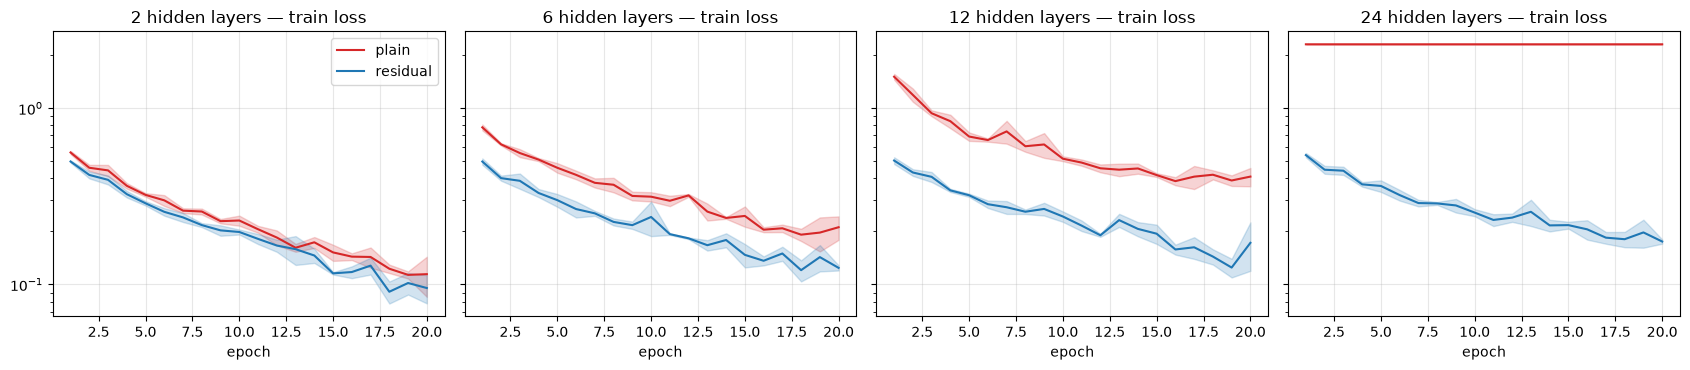

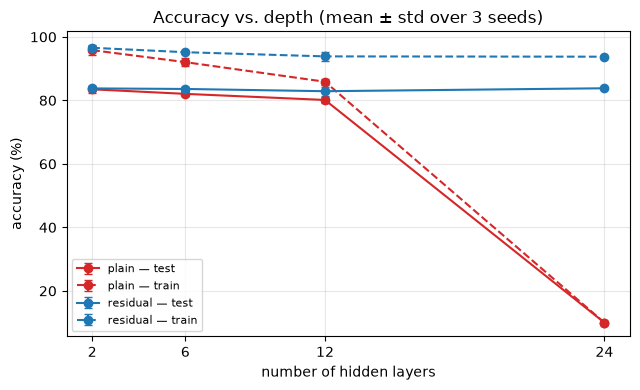

In [19]:
ed = np.arange(1, EPOCHS_D + 1)
fig, axes = plt.subplots(1, len(DEPTHS), figsize=(17, 3.8), sharey=True)
for ax, d in zip(axes, DEPTHS):
    for res, c in ((False, "tab:red"), (True, "tab:blue")):
        curves = np.array([h["train_loss"] for h in res_D[(d, res)]])
        m_, s_ = curves.mean(0), curves.std(0)
        ax.plot(ed, m_, c=c, label="residual" if res else "plain"); ax.fill_between(ed, m_ - s_, m_ + s_, color=c, alpha=.2)
    ax.set(title=f"{d} hidden layers — train loss", xlabel="epoch", yscale="log"); ax.grid(alpha=.3)
axes[0].legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
for res, c, lab in ((False, "tab:red", "plain"), (True, "tab:blue", "residual")):
    for key, ls in (("test_acc", "-"), ("train_acc", "--")):
        vals = np.array([[h[key] if key == "test_acc" else h[key][-1] for h in res_D[(d, res)]] for d in DEPTHS]) * 100
        ax.errorbar(DEPTHS, vals.mean(1), yerr=vals.std(1), fmt="o" + ls, c=c, capsize=3,
                    label=f"{lab} — {'test' if key == 'test_acc' else 'train'}")
ax.set(xlabel="number of hidden layers", ylabel="accuracy (%)", title="Accuracy vs. depth (mean ± std over 3 seeds)", xticks=DEPTHS)
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Observations (Part D)**
* For **shallow** networks (2 hidden layers) plain and residual MLPs behave almost identically — the skip connection is not needed.
* As depth grows, the **plain** MLP gets *harder to optimise*: its final training loss rises from 0.11 (2 layers) to 0.41 (12 layers), and at 24 layers it does not train at all (loss stays at ln 10 = 2.30, 10 % accuracy — chance level),
  even though it has exactly the same parameters as the residual one. This is the **degradation problem** — caused by vanishing
  gradients (see the gradient-norm table), not by overfitting, since training accuracy falls too.
* The **residual** MLP keeps training well at every depth (83.8 % test at 24 layers) because the identity shortcut gives gradients a direct path to early
  layers and lets each layer learn a small correction $f(h)$ rather than a full transformation.

---
## Conclusion

| Topic | Key finding |
|---|---|
| GD variants | Mini-batch GD combines SGD's many cheap updates with batch GD's stable gradient; gradient noise ∝ 1/√(batch size). |
| Optimizers | Momentum/Nesterov reach 85 % val in half the epochs of SGD; RMSprop/Adam converge fastest early; step/cosine schedules add 1.3–4.5 pp test accuracy for every optimizer (best: RMSprop + step, 85.71 %). |
| Overfitting | A 670 k-parameter MLP on 6 000 images memorises them (99 % train vs 85 % val). Dropout gives the best accuracy (85.43 %); L2 and augmentation mainly shrink the gap and the validation loss. |
| Early stopping | Restoring the lowest-validation-loss weights (epoch 6) cuts training by 73 % and gives a much better-calibrated model (val loss 0.42 vs 1.07). |
| Residual MLPs | With identical parameters and training, plain MLPs degrade with depth and fail completely at 24 layers (10 %), while residual MLPs stay at ~83–84 %. |